📂 Please upload your climate dataset CSV file


Saving TerraClimate_Jabalpur_1958_2023_monthly.csv to TerraClimate_Jabalpur_1958_2023_monthly.csv
✅ Dataset loaded, first 5 rows:
         date  pdsi   pet  ppt  soil    tmmn    tmmx   tmean
0  1958-01-01   -30   821    7   994 -262.05 -246.25 -254.15
1  1958-02-01   -80  1049    2   637 -261.05 -243.65 -252.35
2  1958-03-01   -89  1496   11   479 -256.25 -238.75 -247.50
3  1958-04-01   -85  1888    6   387 -250.25 -233.25 -241.75
4  1958-05-01  -112  2219    1   325 -246.15 -230.65 -238.40

📊 Time series preview:
             tmean
date              
1958-01-01 -254.15
1958-02-01 -252.35
1958-03-01 -247.50
1958-04-01 -241.75
1958-05-01 -238.40


/tmp/ipython-input-2404955400.py:45: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  ts[target_col] = pd.to_numeric(ts[target_col], errors="coerce").interpolate().fillna(method="bfill")


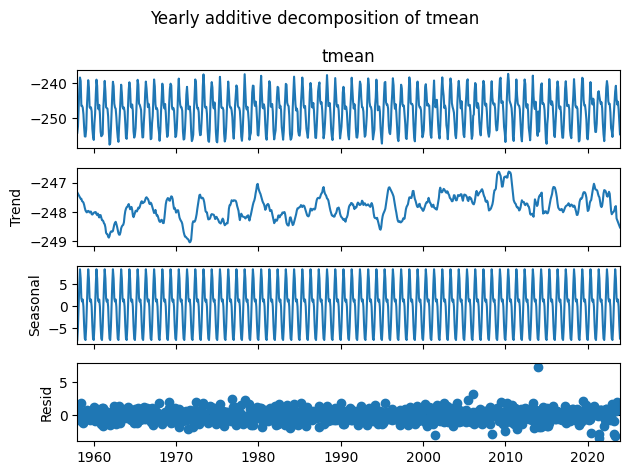

ADF p-value: 0.00000
📈 Train size: 633, Test size: 159
                                     SARIMAX Results                                      
Dep. Variable:                              tmean   No. Observations:                  633
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -807.151
Date:                            Thu, 20 Nov 2025   AIC                           1624.303
Time:                                    14:03:35   BIC                           1646.337
Sample:                                01-01-1958   HQIC                          1632.877
                                     - 09-01-2010                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2392      0.043      5.621      0.000     

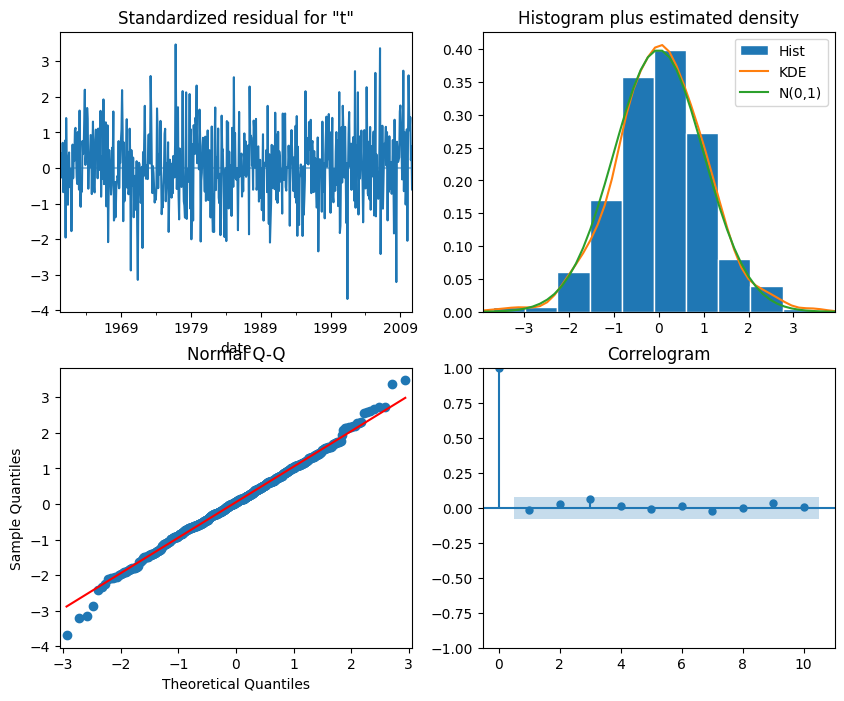


📏 Model Evaluation Metrics:
RMSE: 1.304
MAE:  0.936
MAPE: 0.38%
R²:   0.931


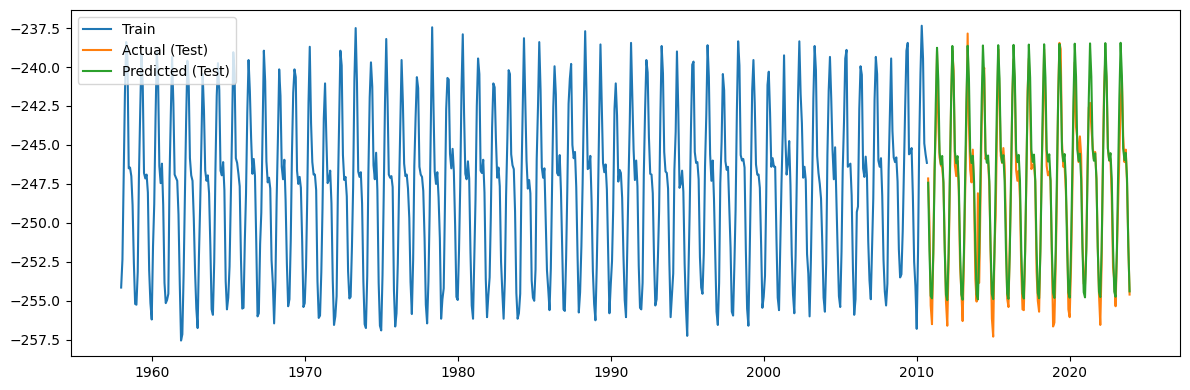

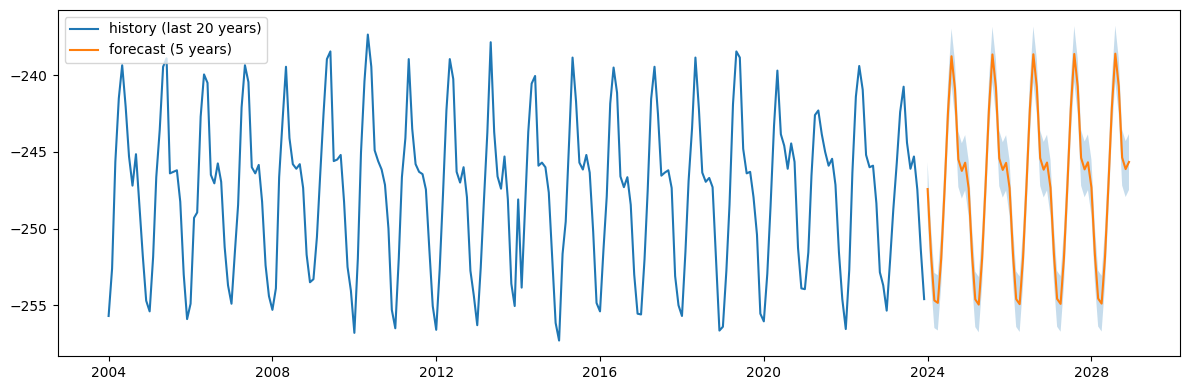


✅ Saved all outputs (metrics, plots, forecasts) to: tsa_climate_outputs


In [5]:
# --- Install dependencies (if not already installed) ---
!pip install statsmodels

# --- Imports ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from pathlib import Path
from google.colab import files

# --- Step 0: Ask for dataset upload ---
print("📂 Please upload your climate dataset CSV file")
uploaded = files.upload()

# Get file path
DATA_PATH = list(uploaded.keys())[0]

# --- Output folder ---
OUT = Path("tsa_climate_outputs")
OUT.mkdir(parents=True, exist_ok=True)

# --- Step 1: Load dataset ---
df = pd.read_csv(DATA_PATH)
print("✅ Dataset loaded, first 5 rows:")
print(df.head())

# --- Step 2: Choose target variable ---
# Example: 'tmean' (temperature) or 'precipitation')
target_col = "tmean"

# Ensure datetime column exists
if "date" in df.columns:
    df["date"] = pd.to_datetime(df["date"])
    ts = df.set_index("date")[[target_col]]
else:
    df["date"] = pd.to_datetime(df["year"].astype(str) + "-" + df["month"].astype(str) + "-01")
    ts = df.set_index("date")[[target_col]]

ts = ts.sort_index()
ts = ts.asfreq("MS")
ts[target_col] = pd.to_numeric(ts[target_col], errors="coerce").interpolate().fillna(method="bfill")

print("\n📊 Time series preview:")
print(ts.head())

# --- Step 3: Seasonal decomposition ---
decomp = seasonal_decompose(ts[target_col], model="additive", period=12, extrapolate_trend="freq")
decomp.plot().suptitle(f"Yearly additive decomposition of {target_col}")
plt.tight_layout()
plt.savefig(OUT / f"decompose_{target_col}.png")
plt.show()

# --- Step 4: Stationarity test ---
p_value = adfuller(ts[target_col].dropna())[1]
print(f"ADF p-value: {p_value:.5f}")

# --- Step 5: Train-test split (80/20 if long enough) ---
if len(ts) > 120:
    train_size = int(len(ts) * 0.8)
    train, test = ts.iloc[:train_size], ts.iloc[train_size:]
    print(f"📈 Train size: {len(train)}, Test size: {len(test)}")
else:
    train, test = ts, None
    print("⚠️ Not enough data for test split; training on full dataset.")

# --- Step 6: SARIMA model ---
order = (1,1,1)
seasonal_order = (1,1,1,12)

model = sm.tsa.SARIMAX(train[target_col],
                       order=order,
                       seasonal_order=seasonal_order,
                       enforce_stationarity=False,
                       enforce_invertibility=False)
res = model.fit(disp=False, maxiter=100)
print(res.summary())

res.plot_diagnostics(figsize=(10,8))
plt.savefig(OUT / f"diagnostics_{target_col}.png")
plt.show()

# --- Step 7: Evaluation (if test data exists) ---
if test is not None:
    pred = res.get_forecast(steps=len(test))
    pred_mean = pred.predicted_mean
    test_values = test[target_col]

    # Metrics
    rmse = np.sqrt(mean_squared_error(test_values, pred_mean))
    mae = mean_absolute_error(test_values, pred_mean)
    mape = np.mean(np.abs((test_values - pred_mean) / test_values)) * 100
    r2 = r2_score(test_values, pred_mean)

    print("\n📏 Model Evaluation Metrics:")
    print(f"RMSE: {rmse:.3f}")
    print(f"MAE:  {mae:.3f}")
    print(f"MAPE: {mape:.2f}%")
    print(f"R²:   {r2:.3f}")

    metrics_df = pd.DataFrame({
        "Metric": ["RMSE", "MAE", "MAPE", "R2"],
        "Value": [rmse, mae, mape, r2]
    })
    metrics_df.to_csv(OUT / f"metrics_{target_col}.csv", index=False)

    # Plot test vs predicted
    plt.figure(figsize=(12,4))
    plt.plot(train.index, train[target_col], label="Train")
    plt.plot(test.index, test_values, label="Actual (Test)")
    plt.plot(test.index, pred_mean, label="Predicted (Test)")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUT / f"test_forecast_{target_col}.png")
    plt.show()

# --- Step 8: Forecast next 5 years ---
steps = 60
pred_future = res.get_forecast(steps=steps)
pred_ci = pred_future.conf_int()
dates = pd.date_range(ts.index[-1] + pd.offsets.MonthBegin(1), periods=steps, freq="MS")

forecast = pd.DataFrame({
    "date": dates,
    "forecast": pred_future.predicted_mean.values,
    "lower": pred_ci.iloc[:,0].values,
    "upper": pred_ci.iloc[:,1].values
})
forecast.to_csv(OUT / f"forecast_{target_col}.csv", index=False)

# --- Step 9: Forecast plot ---
plt.figure(figsize=(12,4))
plt.plot(ts[target_col][-240:], label="history (last 20 years)")
plt.plot(dates, forecast["forecast"], label="forecast (5 years)")
plt.fill_between(dates, forecast["lower"], forecast["upper"], alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(OUT / f"forecast_plot_{target_col}.png")
plt.show()

print("\n✅ Saved all outputs (metrics, plots, forecasts) to:", OUT)



📌 Continuing from SARIMA — starting LSTM & GRU modeling...
Train samples: 604, Test samples: 152

🔵 Training LSTM...
Epoch 1/60


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 60ms/step - loss: 0.1898 - val_loss: 0.0705
Epoch 2/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - loss: 0.0764 - val_loss: 0.0685
Epoch 3/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 0.0688 - val_loss: 0.0680
Epoch 4/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - loss: 0.0655 - val_loss: 0.0614
Epoch 5/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 0.0643 - val_loss: 0.0556
Epoch 6/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - loss: 0.0534 - val_loss: 0.0452
Epoch 7/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - loss: 0.0417 - val_loss: 0.0253
Epoch 8/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - loss: 0.0174 - val_loss: 0.0183
Epoch 9/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - loss: 0.0151 - val_loss: 0.0139
Epoch 10/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 0.0119 - val_loss: 0.0117
Epoch 11/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 0.0113 - val_loss: 0.0115
Epoch 12/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 0.0093 - val_l

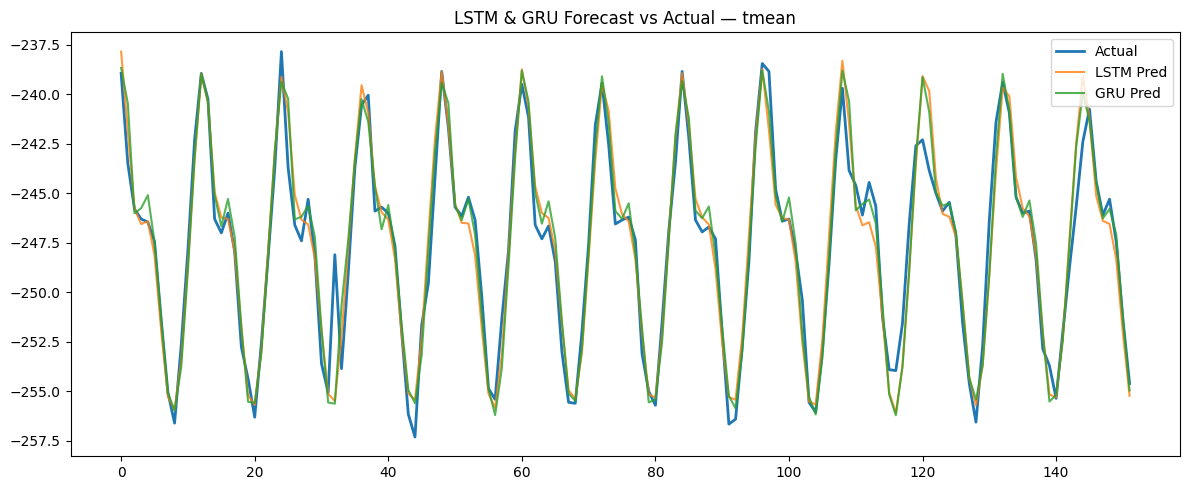


📁 Saved predictions and outputs to: outputs_ts_models/lstm_gru_results_tmean.csv
🎉 LSTM & GRU modeling completed!


In [8]:
# --- Install TensorFlow ---
!pip install tensorflow

# --- Imports ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("📌 Continuing from SARIMA — starting LSTM & GRU modeling...")

# --- Step 1: Use the SAME ts and target_col from previous block ---
# ts     -> your time series dataframe (index = date)
# target -> target_col defined earlier

series = ts[target_col].values.reshape(-1,1)

# --- Step 2: Scaling ---
scaler = MinMaxScaler()
scaled = scaler.fit_transform(series)

# --- Step 3: Create sequences ---
LOOKBACK = 36  # use 3 years history

def make_sequences(data, lookback):
    X, y = [], []
    for i in range(lookback, len(data)):
        X.append(data[i - lookback:i, 0])
        y.append(data[i, 0])
    return np.array(X), np.array(y)

X, y = make_sequences(scaled, LOOKBACK)
X = X.reshape((X.shape[0], X.shape[1], 1))

# --- Step 4: Train-test split (same 80/20 logic) ---
SPLIT = int(len(X) * 0.8)
X_train, X_test = X[:SPLIT], X[SPLIT:]
y_train, y_test = y[:SPLIT], y[SPLIT:]

print(f"Train samples: {len(X_train)}, Test samples: {len(X_test)}")

# --- Step 5: Build LSTM model ---
def make_LSTM():
    model = Sequential([
        LSTM(64, return_sequences=True, input_shape=(LOOKBACK, 1)),
        Dropout(0.2),
        LSTM(32),
        Dense(1)
    ])
    model.compile(optimizer="adam", loss="mse")
    return model

# --- Step 6: Build GRU model ---
def make_GRU():
    model = Sequential([
        GRU(64, return_sequences=True, input_shape=(LOOKBACK, 1)),
        Dropout(0.2),
        GRU(32),
        Dense(1)
    ])
    model.compile(optimizer="adam", loss="mse")
    return model

# --- Step 7: Training (same callback for both) ---
early = EarlyStopping(patience=10, restore_best_weights=True)

print("\n🔵 Training LSTM...")
lstm = make_LSTM()
hist_lstm = lstm.fit(X_train, y_train, epochs=60, batch_size=32,
                     validation_split=0.1, callbacks=[early], verbose=1)

print("\n🟣 Training GRU...")
gru = make_GRU()
hist_gru = gru.fit(X_train, y_train, epochs=60, batch_size=32,
                   validation_split=0.1, callbacks=[early], verbose=1)

# --- Step 8: Predictions ---
pred_lstm_scaled = lstm.predict(X_test).flatten()
pred_gru_scaled = gru.predict(X_test).flatten()

# Inverse-scale
y_test_real = scaler.inverse_transform(y_test.reshape(-1,1)).flatten()
pred_lstm_real = scaler.inverse_transform(pred_lstm_scaled.reshape(-1,1)).flatten()
pred_gru_real = scaler.inverse_transform(pred_gru_scaled.reshape(-1,1)).flatten()

# --- Step 9: Metrics ---
def metrics(y_true, pred):
    rmse = np.sqrt(mean_squared_error(y_true, pred))
    mae = mean_absolute_error(y_true, pred)
    mape = np.mean(np.abs((y_true - pred) / y_true)) * 100
    r2 = r2_score(y_true, pred)
    return rmse, mae, mape, r2

lstm_scores = metrics(y_test_real, pred_lstm_real)
gru_scores = metrics(y_test_real, pred_gru_real)

print("\n📏 LSTM Metrics:", lstm_scores)
print("📏 GRU Metrics: ", gru_scores)

# --- Step 10: Plot predictions ---
plt.figure(figsize=(12,5))
plt.plot(y_test_real, label="Actual", linewidth=2)
plt.plot(pred_lstm_real, label="LSTM Pred", alpha=0.8)
plt.plot(pred_gru_real, label="GRU Pred", alpha=0.8)
plt.legend()
plt.title(f"LSTM & GRU Forecast vs Actual — {target_col}")
plt.tight_layout()
plt.show()

# --- Step 11: Save results ---
OUT_LSTM = OUT / f"lstm_gru_results_{target_col}.csv"
pd.DataFrame({
    "actual": y_test_real,
    "lstm_pred": pred_lstm_real,
    "gru_pred": pred_gru_real
}).to_csv(OUT_LSTM, index=False)

print(f"\n📁 Saved predictions and outputs to: {OUT_LSTM}")
print("🎉 LSTM & GRU modeling completed!")


In [9]:
# -----------------------------------------
# EXTRA METRICS: MSE, RMSE, MAE, MAPE, R2, MBE
# -----------------------------------------

import numpy as np
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

def mean_bias_error(y_true, y_pred):
    return np.mean(y_pred - y_true)

print("📊 Computing additional metrics (MSE, RMSE, MAE, MAPE, R2, MBE)...")

# Already available from previous cell:
# y_test_real
# pred_lstm_real
# pred_gru_real

def compute_all_metrics(y_true, y_pred):
    mse  = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae  = mean_absolute_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    r2   = r2_score(y_true, y_pred)
    mbe  = mean_bias_error(y_true, y_pred)

    return {
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "MAPE": mape,
        "R2 Score": r2,
        "MBE": mbe
    }

# LSTM metrics
metrics_lstm_full = compute_all_metrics(y_test_real, pred_lstm_real)

# GRU metrics
metrics_gru_full = compute_all_metrics(y_test_real, pred_gru_real)

# Display results
print("\n🔵 LSTM Metrics:")
for k,v in metrics_lstm_full.items():
    print(f"{k}: {v:.4f}")

print("\n🟣 GRU Metrics:")
for k,v in metrics_gru_full.items():
    print(f"{k}: {v:.4f}")

# Save to CSV
metrics_df = pd.DataFrame([
    {"Model": "LSTM", **metrics_lstm_full},
    {"Model": "GRU",  **metrics_gru_full}
])

metrics_df.to_csv(OUT / f"extra_metrics_lstm_gru_{target_col}.csv", index=False)
print(f"\n💾 Saved metrics to: {OUT}/extra_metrics_lstm_gru_{target_col}.csv")


📊 Computing additional metrics (MSE, RMSE, MAE, MAPE, R2, MBE)...

🔵 LSTM Metrics:
MSE: 1.8638
RMSE: 1.3652
MAE: 0.9847
MAPE: 0.3986
R2 Score: 0.9246
MBE: 0.0502

🟣 GRU Metrics:
MSE: 1.7551
RMSE: 1.3248
MAE: 0.9359
MAPE: 0.3783
R2 Score: 0.9290
MBE: 0.1335

💾 Saved metrics to: outputs_ts_models/extra_metrics_lstm_gru_tmean.csv
